<a href="https://colab.research.google.com/github/mabrarbel-eng/DSC110/blob/main/DSC110_Data_Visualization_Commented.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Import pandas to organize and analyze tabular data in a DataFrame.
# Import matplotlib.pyplot as plt so we can create and customize charts.

import pandas as pd
import matplotlib.pyplot as plt


In [ ]:
# Read the NHANES dataset directly from the course GitHub repository.
# The resulting DataFrame, df, will be used in the examples below.

df = pd.read_csv("https://raw.githubusercontent.com/osoliman/DSC110/refs/heads/main/Datasets/nhanes_final.csv")


In [ ]:
# Display the first five rows to preview the dataset and check its columns and values.

df.head()


,id,gender,age,race_ethnicity,education,bmi,height_cm,systolic_bp,has_diabetes,hba1c,fasting_glucose
0,130378.0,1.0,43.0,6.0,5.0,27.0,179.5,135.0,2.0,5.6,113.0
1,130379.0,1.0,66.0,3.0,5.0,33.5,174.2,121.0,2.0,5.6,99.0
2,130380.0,2.0,44.0,2.0,3.0,29.7,152.9,111.0,1.0,6.2,156.0
3,130381.0,2.0,5.0,7.0,NaN,23.8,120.1,NaN,2.0,NaN,NaN
4,130382.0,1.0,2.0,3.0,NaN,NaN,NaN,NaN,2.0,NaN,NaN


Transforming variables

In [ ]:
# Show the distinct values recorded in the education column.
# This helps us understand the numeric codes before translating them into readable labels.

df['education'].unique()


array([ 5.,  3., nan,  2.,  4.,  1.,  9.])

In [ ]:
# Create a dictionary that pairs each education code with a descriptive category.
# The dictionary will let pandas replace numeric codes with labels that are easier to interpret.

education_map = {
    1: 'Less than 9th grade',
    2: '9-11th grade',
    3: 'High school grad',
    4: 'Some college or AA degree',
    5: 'College grad',
    9: 'Do not know'
}


In [ ]:
# Map the education codes to their text labels and store the result in a new column.
# Keeping the original education column preserves the source values.

df['education_label'] = df['education'].map(education_map)


In [ ]:
# Preview the DataFrame to confirm that the new education_label column was added.

df.head()


,id,gender,age,race_ethnicity,education,bmi,height_cm,systolic_bp,has_diabetes,hba1c,fasting_glucose,education_label
0,130378.0,1.0,43.0,6.0,5.0,27.0,179.5,135.0,2.0,5.6,113.0,College grad
1,130379.0,1.0,66.0,3.0,5.0,33.5,174.2,121.0,2.0,5.6,99.0,College grad
2,130380.0,2.0,44.0,2.0,3.0,29.7,152.9,111.0,1.0,6.2,156.0,High school grad
3,130381.0,2.0,5.0,7.0,NaN,23.8,120.1,NaN,2.0,NaN,NaN,NaN
4,130382.0,1.0,2.0,3.0,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN


In [ ]:
# Count how many respondents fall into each education category.
# By default, value_counts sorts the categories from most frequent to least frequent.

df['education_label'].value_counts()


,count
education_label,
College grad,2625
Some college or AA degree,2370
High school grad,1749
9-11th grade,666
Less than 9th grade,373
Do not know,11


In [ ]:
# Task note: create readable labels for the has_diabetes codes.
# Codes: 1 = has Diabetes, 2 = No Diabetes, 3 = Borderline, and 9 = Do not know.
# The new column should be named diabetes_label.

#Do the same for has_diabetes field
# 1 = has Diabetes, 2= No Diabetes, 3 = Borderline, 9 = Do not know
#Name the new field diabetes_label


In [ ]:
# Define the meaning of each numeric diabetes code in a dictionary.
# Apply the dictionary to has_diabetes and save the readable categories in diabetes_label.

diabetes_map = {
    1: 'has Diabetes',
    2: 'No Diabetes',
    3: 'Borderline',
    9: 'Do not know'
}

df['diabetes_label'] = df['has_diabetes'].map(diabetes_map)


In [ ]:
# Count respondents in each diabetes category to summarize the distribution.

df['diabetes_label'].value_counts()


,count
diabetes_label,
No Diabetes,10371
has Diabetes,1081
Borderline,284
Do not know,4


Data Summarization

One Numerical Value

In [ ]:
# Calculate the mean age, round it to two decimal places, and store it in avg_age.
# Print a sentence with the result so the summary is easy to read.

#Numerical varaibles in our data
avg_age = round(df['age'].mean(),2)
print(f"The average age of NHANES respondents is {avg_age}")


The average age of NHANES respondents is 38.32


In [ ]:
# Calculate the standard deviation of age, which describes how spread out ages are around the mean.
# A larger standard deviation indicates more variability in respondent ages.

df['age'].std()


25.60199011389104

In [ ]:
# Calculate the median age, the middle value when ages are ordered.
# The median is less affected by unusually high or low values than the mean.

df['age'].median()


37.0

In [ ]:
# Calculate the 25th percentile (first quartile) of age.
# About 25% of observations are at or below this value.

df['age'].quantile([0.25])


,age
0.25,13.0


In [ ]:
# Calculate the 75th percentile (third quartile) of age.
# About 75% of observations are at or below this value.

df['age'].quantile([0.75])


,age
0.75,62.0


In [ ]:
# describe() returns several summary statistics, including count, mean, standard deviation, minimum, and quartiles.
# apply(format(..., 'f')) formats the displayed values without scientific notation.

#df['age'].describe()
df['age'].describe().apply(lambda x: format(x, 'f'))
#without scientific notation


,age
count,11933.000000
mean,38.317858
std,25.601990
min,0.000000
25%,13.000000
50%,37.000000
75%,62.000000
max,80.000000


In [ ]:
# Find the mode(s) of age: the age value or values that occur most often.
# There can be more than one mode if multiple ages share the highest frequency.

df['age'].mode()


,age
0,80.0


Data Visualization for one numeric variable

<Axes: >

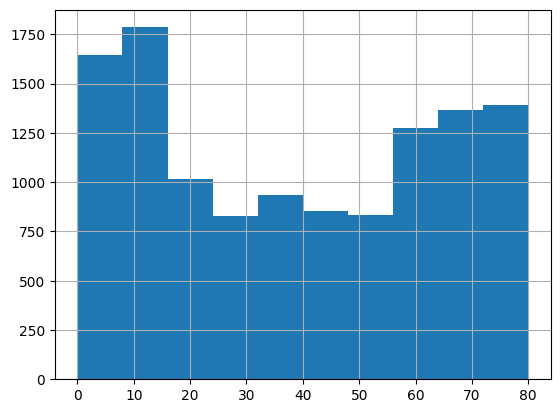

In [ ]:
# Draw a histogram of age to show how respondents' ages are distributed.
# The histogram groups numeric ages into intervals and displays the number of observations in each interval.

df['age'].hist()


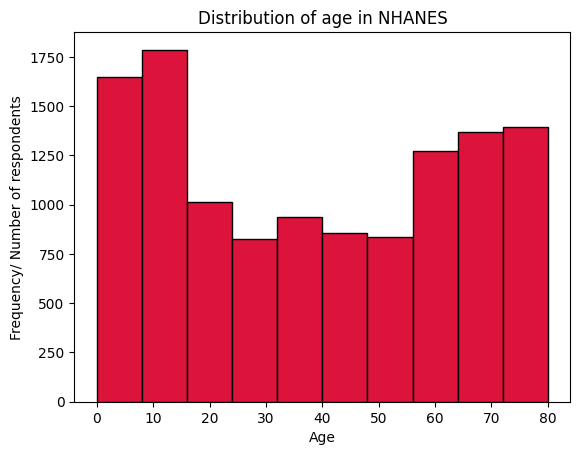

In [ ]:
# Draw the age histogram and customize its bar outlines and color.
# Add a title and axis labels so the chart is clear to readers.
# Turn off the grid to keep the plot visually uncluttered.

df['age'].hist(edgecolor = 'black', color = 'crimson')
plt.title("Distribution of age in NHANES")
plt.ylabel("Frequency/ Number of respondents")
plt.xlabel("Age")
plt.grid(False)


Summarization and Visualization of One categorical/qualitative variable

In [ ]:
# Count the number of respondents in each education category.
# This is a frequency summary for the categorical education variable.

df['education_label'].value_counts()


,count
education_label,
College grad,2625
Some college or AA degree,2370
High school grad,1749
9-11th grade,666
Less than 9th grade,373
Do not know,11


In [ ]:
# Calculate the percentage in each education category.
# normalize=True converts counts to proportions; multiplying by 100 converts proportions to percentages.

df['education_label'].value_counts(normalize=True) * 100


,proportion
education_label,
College grad,33.679754
Some college or AA degree,30.408006
High school grad,22.440339
9-11th grade,8.545035
Less than 9th grade,4.785733
Do not know,0.141134


Text(0, 0.5, 'Number of respondents/Freuency')

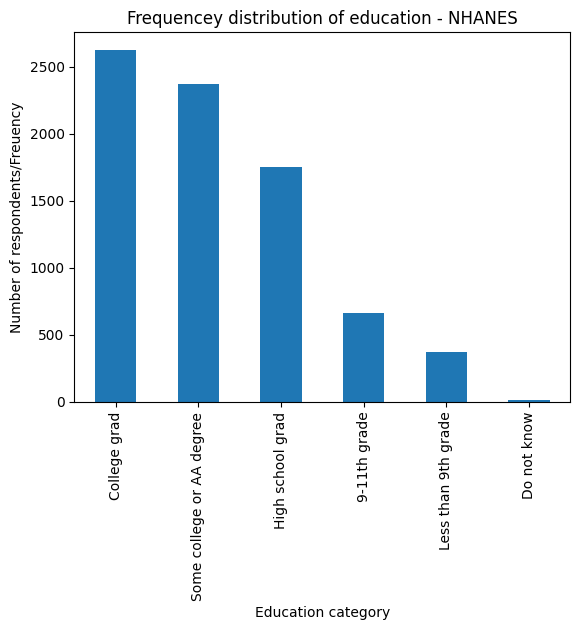

In [ ]:
# Plot the education category counts as a bar chart.
# Add a title and axis labels to identify the categories and their frequencies.

df['education_label'].value_counts().plot(kind='bar')
plt.title('Frequencey distribution of education - NHANES')
plt.xlabel('Education category')
plt.ylabel('Number of respondents/Freuency')


Two numerical variables

<Axes: xlabel='fasting_glucose', ylabel='hba1c'>

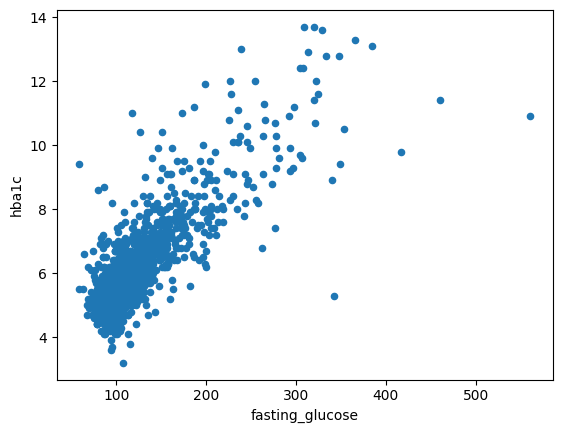

In [ ]:
# Create a scatter plot comparing fasting glucose with HbA1c.
# Each point represents an observation, helping us look for a relationship between the two numeric variables.

df.plot(x='fasting_glucose', y='hba1c', kind='scatter')


<Axes: xlabel='fasting_glucose', ylabel='hba1c'>

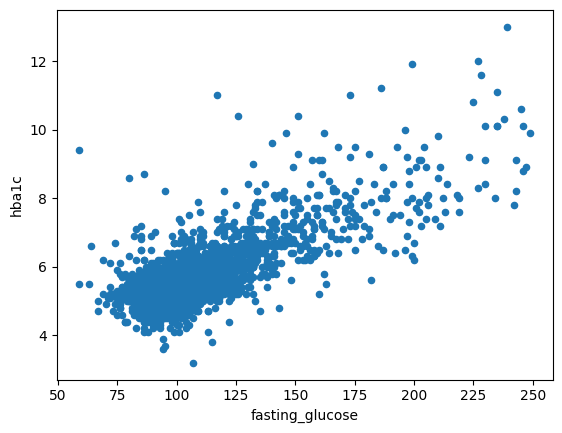

In [ ]:
# Create a filtered DataFrame containing rows with fasting glucose below 250.
# This excludes very high fasting-glucose values from this particular plot; it does not change the original df.
# Plot the filtered fasting-glucose values against HbA1c to inspect the relationship with those values excluded.

df_no_outliers = df[df['fasting_glucose']<250]
df_no_outliers.plot(x='fasting_glucose', y='hba1c', kind='scatter')


Two categorical values

In [ ]:
# Divide BMI into four categories using the specified cut points.
# The labels describe underweight, normal, overweight, and obese ranges.
# pd.cut assigns each BMI value to a category; values outside the specified bins become missing.

df['bmi_category'] = pd.cut(df['bmi'],
                            bins = [0, 18.5, 25, 30, 100],
                            labels = ['Underweight', 'Normal', 'Overweight', 'Obese']
                            )


In [ ]:
# Create a cross-tabulation of BMI category by diabetes label.
# normalize='index' calculates percentages within each BMI category, so each row is interpreted across diabetes categories.
# Multiplying by 100 expresses the results as percentages.

pd.crosstab(df['bmi_category'], df['diabetes_label'], normalize='index') * 100


diabetes_label,Borderline,Do not know,No Diabetes,has Diabetes
bmi_category,,,,
Underweight,0.000000,0.082237,99.588816,0.328947
Normal,1.625000,0.041667,93.791667,4.541667
Overweight,3.197807,0.000000,86.158063,10.644130
Obese,4.501125,0.000000,76.594149,18.904726


<Axes: xlabel='bmi_category'>

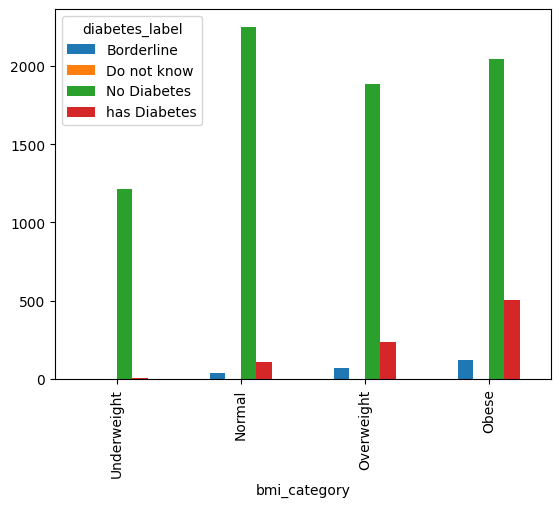

In [ ]:
# Count respondents for each combination of BMI category and diabetes label.
# Plot those counts as bars to compare the diabetes categories across BMI groups.

pd.crosstab(df['bmi_category'], df['diabetes_label']).plot(kind = 'bar')


One numerical and one categorical

In [ ]:
# Group respondents by diabetes category and calculate the mean BMI within each group.
# This helps compare average BMI across the diabetes labels.

df.groupby('diabetes_label')['bmi'].mean()


,bmi
diabetes_label,
Borderline,32.068559
Do not know,19.250000
No Diabetes,26.439797
has Diabetes,32.981412


Text(0, 0.5, 'BMI')

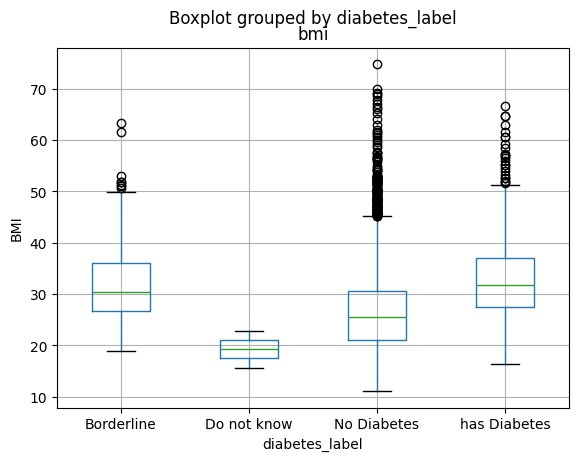

In [ ]:
# Draw a boxplot of BMI grouped by diabetes label.
# Boxplots summarize the median, quartiles, spread, and potential outliers in each group.
# Label the vertical axis so the measurement is clear.

#Boxplot
df.boxplot(column='bmi', by='diabetes_label')
plt.ylabel('BMI')


In [ ]:
# Install the tableone package in the notebook environment.
# In Colab, this command installs the package if it is not already available.

!pip install tableone


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 1.8 MB/s eta 0:00:00


In [ ]:
# Import tableone so its TableOne summary-table function can be used below.

import tableone


In [ ]:
# Create a TableOne summary table for the DataFrame.
# This provides descriptive summaries of the dataset's variables.

tableone.TableOne(df)


Missing            Overall
n                                                                         11933
id, mean (SD)                                              0  136344.0 (3444.9)
gender, n (%)              1.0                                      5575 (46.7)
                           2.0                                      6358 (53.3)
age, mean (SD)                                             0        38.3 (25.6)
race_ethnicity, n (%)      1.0                                       1117 (9.4)
                           2.0                                      1373 (11.5)
                           3.0                                      6217 (52.1)
                           4.0                                      1597 (13.4)
                           6.0                                        681 (5.7)
                           7.0                                        948 (7.9)
education, n (%)           1.0                                        373 (3.1)
                           2.0                                        666 (5.6)
                           3.0                                      1749 (14.7)
                           4.0                                      2370 (19.9)
                           5.0                                      2625 (22.0)
                           9.0                                         11 (0.1)
                           None                                     4139 (34.7)
bmi, mean (SD)                                          3462         27.2 (8.1)
height_cm, mean (SD)                                    3434       159.7 (19.9)
systolic_bp, mean (SD)                                  4416       119.3 (18.6)
has_diabetes, n (%)        1.0                                       1081 (9.1)
                           2.0                                     10371 (86.9)
                           3.0                                        284 (2.4)
                           9.0                                          4 (0.0)
                           None                                       193 (1.6)
hba1c, mean (SD)                                        5218          5.7 (1.1)
fasting_glucose, mean (SD)                              8261       107.9 (32.5)
education_label, n (%)     9-11th grade                               666 (5.6)
                           College grad                             2625 (22.0)
                           Do not know                                 11 (0.1)
                           High school grad                         1749 (14.7)
                           Less than 9th grade                        373 (3.1)
                           None                                     4139 (34.7)
                           Some college or AA degree                2370 (19.9)
diabetes_label, n (%)      Borderline                                 284 (2.4)
                           Do not know                                  4 (0.0)
                           No Diabetes                             10371 (86.9)
                           None                                       193 (1.6)
                           has Diabetes                              1081 (9.1)
bmi_category, n (%)        Underweight                              1216 (10.2)
                           Normal                                   2400 (20.1)
                           Overweight                               2189 (18.3)
                           Obese                                    2666 (22.3)
                           None                                     3462 (29.0)

In [ ]:
# Create a TableOne summary table and treat age as a non-normally distributed variable.
# show_histograms=True requests histograms to help inspect variable distributions.

tableone.TableOne(df, nonnormal=['age'], show_histograms = True)


Missing            Overall Histogram
n                                                                         11933          
id, mean (SD)                                              0  136344.0 (3444.9)  █▇▇▇▇▇▇█
gender, n (%)              1.0                                      5575 (46.7)          
                           2.0                                      6358 (53.3)          
age, median [Q1,Q3]                                        0   37.0 [13.0,62.0]  █▇▃▄▄▄▆▆
race_ethnicity, n (%)      1.0                                       1117 (9.4)          
                           2.0                                      1373 (11.5)          
                           3.0                                      6217 (52.1)          
                           4.0                                      1597 (13.4)          
                           6.0                                        681 (5.7)          
                           7.0                                        948 (7.9)          
education, n (%)           1.0                                        373 (3.1)          
                           2.0                                        666 (5.6)          
                           3.0                                      1749 (14.7)          
                           4.0                                      2370 (19.9)          
                           5.0                                      2625 (22.0)          
                           9.0                                         11 (0.1)          
                           None                                     4139 (34.7)          
bmi, mean (SD)                                          3462         27.2 (8.1)  ▅▆█▆▃▂▁▁
height_cm, mean (SD)                                    3434       159.7 (19.9)  ▁▁▁▁▃█▇▃
systolic_bp, mean (SD)                                  4416       119.3 (18.6)  ▃▆█▅▃▂▁▁
has_diabetes, n (%)        1.0                                       1081 (9.1)          
                           2.0                                     10371 (86.9)          
                           3.0                                        284 (2.4)          
                           9.0                                          4 (0.0)          
                           None                                       193 (1.6)          
hba1c, mean (SD)                                        5218          5.7 (1.1)  ▄█▂▁▁▁▁▁
fasting_glucose, mean (SD)                              8261       107.9 (32.5)  █▅▁▁▁▁▁▁
education_label, n (%)     9-11th grade                               666 (5.6)          
                           College grad                             2625 (22.0)          
                           Do not know                                 11 (0.1)          
                           High school grad                         1749 (14.7)          
                           Less than 9th grade                        373 (3.1)          
                           None                                     4139 (34.7)          
                           Some college or AA degree                2370 (19.9)          
diabetes_label, n (%)      Borderline                                 284 (2.4)          
                           Do not know                                  4 (0.0)          
                           No Diabetes                             10371 (86.9)          
                           None                                       193 (1.6)          
                           has Diabetes                              1081 (9.1)          
bmi_category, n (%)        Underweight                              1216 (10.2)          
                           Normal                                   2400 (20.1)          
                           Overweight                               2189 (18.3)          
                           Obese                                    2666 (22.3)          
   